# Steam Gaming Market Analysis
**Question:** What does the PC game market look like, and what separates the games that reach a large audience from the rest?

**Data:** [Steam Games Dataset](https://huggingface.co/datasets/FronkonGames/steam-games-dataset) (MIT license): ~124K games with price, genres, publishers, review counts, estimated owners, playtime and achievements. Owner counts are Steam's estimated *ranges*; this analysis uses the lower bound. Prices are as captured in the dataset snapshot.

**Tools:** SQL (DuckDB): `UNNEST` on array columns, `ROW_NUMBER` top-N-per-group, `MEDIAN`, CASE bucketing, `HAVING` · Python: pandas, matplotlib

## Setup

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

DB = "data/steam.duckdb"   # built by setup_data.py
con = duckdb.connect(DB, read_only=True)

def q(sql):
    """Run a SQL query and return a pandas DataFrame."""
    return con.sql(sql).df()

# Chart style: one blue for single-series charts, quiet axes and grid
BLUE, INK, MUTED, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#d9d8d4", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe8",
    "axes.axisbelow": True, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "axes.titlelocation": "left", "figure.dpi": 110,
})
pd.set_option("display.max_columns", 20)
q("SHOW TABLES")

,name
0,game_genres
1,games


## 1. Releases per year
How crowded is the market? New Steam releases per year.

In [2]:
df = q("""
SELECT year(release_date) AS year, COUNT(*) AS releases
FROM games
WHERE year(release_date) BETWEEN 2010 AND 2024
GROUP BY year
ORDER BY year
""")
df

,year,releases
0,2010,255
1,2011,260
2,2012,322
3,2013,467
4,2014,1523
5,2015,2515
6,2016,4141
7,2017,5921
8,2018,7461
9,2019,7242


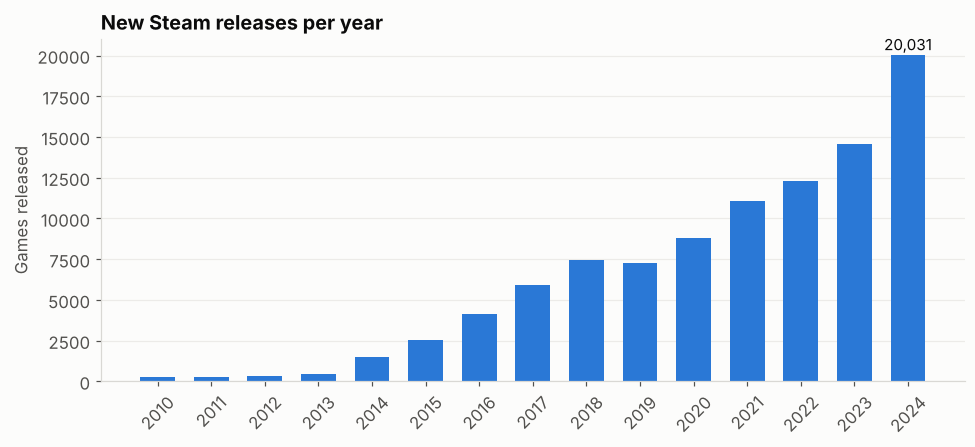

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(df["year"].astype(str), df["releases"], color=BLUE, width=0.65)
ax.text(len(df) - 1, df["releases"].iloc[-1] + 300, f"{df['releases'].iloc[-1]:,}", ha="center", color=INK, fontsize=10)
ax.set_title("New Steam releases per year")
ax.set_ylabel("Games released"); ax.grid(axis="x", visible=False)
plt.setp(ax.get_xticklabels(), rotation=45)
plt.tight_layout(); plt.savefig("images/releases_per_year.png", dpi=150); plt.show()

**Finding:** Annual releases grew from ~250 in 2010 to **20,000+ in 2024**. The market is extremely crowded, so discoverability is the core problem for new games.

## 2. Free vs paid
How do free-to-play and paid games compare on reach and reception? (games with 50+ reviews)

In [4]:
df = q("""
SELECT CASE WHEN price = 0 THEN 'Free' ELSE 'Paid' END                AS model,
       COUNT(*)                                                         AS games,
       ROUND(100.0 * SUM(positive) / SUM(positive + negative), 1)       AS pct_positive_reviews,
       ROUND(100.0 * AVG(CASE WHEN owners_low >= 1000000 THEN 1 ELSE 0 END), 2) AS pct_with_1m_plus_owners
FROM games
WHERE positive + negative >= 50
GROUP BY model
""")
df

,model,games,pct_positive_reviews,pct_with_1m_plus_owners
0,Paid,26560,88.1,4.02
1,Free,4061,80.7,6.82


**Finding:** Free-to-play games are more likely to reach 1M+ owners (6.8% vs 4.0%) but review worse (81% vs 88% positive). Free removes the purchase barrier but attracts less committed players.

## 3. Genre landscape
Which genres have the most games, and which are best received? (games with 50+ reviews)

In [5]:
df = q("""
SELECT gg.genre,
       COUNT(*)                                                         AS games,
       ROUND(AVG(g.price), 2)                                           AS avg_price,
       ROUND(100.0 * SUM(g.positive) / SUM(g.positive + g.negative), 1) AS pct_positive,
       ROUND(MEDIAN(g.median_playtime_forever) / 60.0, 1)               AS median_hours_played
FROM game_genres gg
JOIN games g USING (app_id)
WHERE g.positive + g.negative >= 50
GROUP BY gg.genre
HAVING COUNT(*) >= 300
ORDER BY games DESC
""")
df

,genre,games,avg_price,pct_positive,median_hours_played
0,Indie,21074,4.72,89.4,1.5
1,Adventure,13190,5.49,85.3,1.9
2,Action,12854,5.51,85.0,1.9
3,Casual,10254,4.06,88.3,1.2
4,Simulation,7341,6.56,86.9,2.1
5,RPG,6837,6.54,86.8,2.9
6,Strategy,6674,6.07,86.0,2.8
7,Free To Play,2671,0.09,80.6,0.2
8,Early Access,2223,8.89,86.0,0.8
9,Sports,1320,7.35,80.4,1.3


**Finding:** Indie is by far the largest genre. RPG and Strategy games get the most playtime (~3 median hours), while Massively Multiplayer has the weakest reception (74% positive).

## 4. Pricing vs reception
Do pricier games review better? (paid games with 50+ reviews)

In [6]:
df = q("""
SELECT CASE WHEN price < 5  THEN '1 - Under $5'
            WHEN price < 15 THEN '2 - $5-14.99'
            WHEN price < 30 THEN '3 - $15-29.99'
            WHEN price < 50 THEN '4 - $30-49.99'
            ELSE                 '5 - $50+' END                        AS price_band,
       COUNT(*)                                                         AS games,
       ROUND(MEDIAN(100.0 * positive / (positive + negative)), 1)       AS median_pct_positive,
       ROUND(100.0 * AVG(CASE WHEN owners_low >= 1000000 THEN 1 ELSE 0 END), 2) AS pct_1m_plus_owners
FROM games
WHERE price > 0 AND positive + negative >= 50
GROUP BY price_band
ORDER BY price_band
""")
df

,price_band,games,median_pct_positive,pct_1m_plus_owners
0,1 - Under $5,16155,81.1,3.18
1,2 - $5-14.99,8366,84.5,4.57
2,3 - $15-29.99,1770,83.1,7.46
3,4 - $30-49.99,189,79.2,15.87
4,5 - $50+,80,75.9,11.25


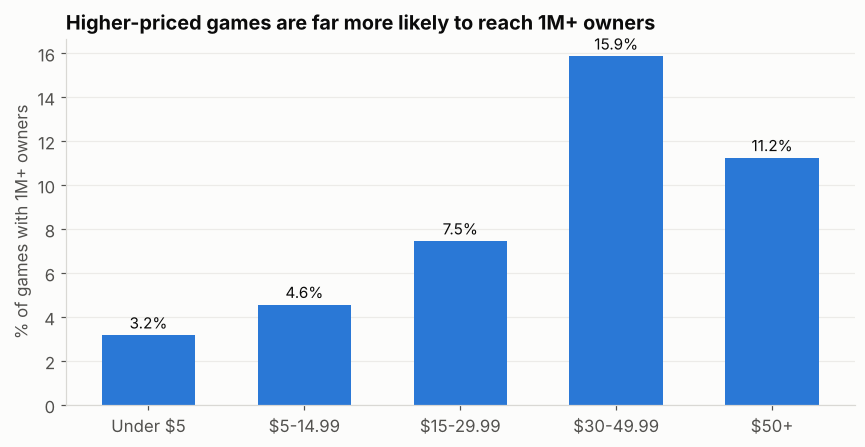

In [7]:
labels = [b.split(" - ")[1] for b in df["price_band"]]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(labels, df["pct_1m_plus_owners"], color=BLUE, width=0.6)
for x, v in enumerate(df["pct_1m_plus_owners"]):
    ax.text(x, v + 0.3, f"{v:.1f}%", ha="center", color=INK, fontsize=10)
ax.set_title("Higher-priced games are far more likely to reach 1M+ owners")
ax.set_ylabel("% of games with 1M+ owners"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig("images/price_vs_hits.png", dpi=150); plt.show()

**Finding:** Higher-priced games are much more likely to be hits (16% of $30–49.99 games reach 1M+ owners vs 3% under $5) but review *slightly worse*. Expectations rise with price.

## 5. Top publishers by hits
Which publishers have the most games with 1M+ estimated owners?

In [8]:
df = q("""
SELECT pub                                   AS publisher,
       COUNT(*)                              AS games_1m_plus,
       SUM(positive + negative)              AS total_reviews
FROM (SELECT UNNEST(publishers) AS pub, positive, negative FROM games WHERE owners_low >= 1000000)
GROUP BY pub
ORDER BY games_1m_plus DESC, total_reviews DESC
LIMIT 10
""")
df

,publisher,games_1m_plus,total_reviews
0,Electronic Arts,52,4533141.0
1,SEGA,39,1493245.0
2,Bethesda Softworks,37,3060190.0
3,Ubisoft,36,3586633.0
4,2K,35,2047753.0
5,Valve,32,16630016.0
6,Xbox Game Studios,25,2088227.0
7,Square Enix,25,1086719.0
8,Activision,23,1544710.0
9,Feral Interactive (Mac),22,1483144.0


**Finding:** Electronic Arts has the most 1M+ owner games, but Valve's 32 hits generate ~4x more reviews than EA's 52. Hit count and hit size are different measures of success.

## 6. Best-reviewed game in each genre
Top game per genre by positive review count. (ROW_NUMBER window function)

In [9]:
df = q("""
WITH ranked AS (
    SELECT gg.genre, g.name, g.positive, g.price,
           ROUND(100.0 * g.positive / (g.positive + g.negative), 1) AS pct_positive,
           ROW_NUMBER() OVER (PARTITION BY gg.genre ORDER BY g.positive DESC) AS rn
    FROM game_genres gg
    JOIN games g USING (app_id)
    WHERE g.positive + g.negative > 0
)
SELECT genre, name, positive AS positive_reviews, pct_positive, price
FROM ranked
WHERE rn = 1 AND genre IN ('Action','Adventure','Casual','Indie','RPG','Simulation','Strategy','Sports','Racing','Free To Play','Massively Multiplayer')
ORDER BY positive_reviews DESC
""")
df

,genre,name,positive_reviews,pct_positive,price
0,Action,Counter-Strike 2,7642084,86.7,0.00
1,Free To Play,Counter-Strike 2,7642084,86.7,0.00
2,Strategy,Dota 2,2037143,81.5,0.00
3,Adventure,Grand Theft Auto V Legacy,1739980,87.4,0.00
4,Massively Multiplayer,PUBG: BATTLEGROUNDS,1520457,59.4,0.00
5,Indie,Terraria,1373979,97.5,4.99
6,RPG,Terraria,1373979,97.5,4.99
7,Casual,Garry's Mod,1122546,96.8,4.99
8,Simulation,Garry's Mod,1122546,96.8,4.99
9,Sports,Rocket League®,509445,87.4,0.00


**Finding:** `ROW_NUMBER() OVER (PARTITION BY genre ...)` returns the top game in each genre in one query. Free-to-play titles (Counter-Strike 2, Dota 2, PUBG) lead most genres by review volume.

## 7. Does content depth drive engagement?
Median hours played by number of achievements (games with 100+ reviews).

In [10]:
df = q("""
SELECT CASE WHEN achievements = 0   THEN '1 - None'
            WHEN achievements <= 20  THEN '2 - 1-20'
            WHEN achievements <= 50  THEN '3 - 21-50'
            ELSE                          '4 - 51+' END AS achievements,
       COUNT(*)                                          AS games,
       ROUND(MEDIAN(median_playtime_forever) / 60.0, 1)  AS median_hours,
       ROUND(MEDIAN(100.0 * positive / (positive + negative)), 1) AS median_pct_positive
FROM games
WHERE positive + negative >= 100
GROUP BY 1
ORDER BY 1
""")
df

,achievements,games,median_hours,median_pct_positive
0,1 - None,6053,1.7,80.2
1,2 - 1-20,6161,2.1,83.8
2,3 - 21-50,7288,3.6,83.3
3,4 - 51+,3299,4.6,83.9


**Finding:** Games with more achievements see ~2.7x more median playtime (4.6 vs 1.7 hours). That's a correlation, not causation: bigger games tend to have both.

## Python cross-check: free vs paid in pandas
Re-computing the free vs. paid comparison in pandas. It should match the SQL result.

In [11]:
g = q("SELECT price, positive, negative, owners_low FROM games WHERE positive + negative >= 50")
g["model"] = g["price"].eq(0).map({True: "Free", False: "Paid"})
summary = g.groupby("model").agg(games=("price", "size"), pos=("positive", "sum"), neg=("negative", "sum"),
                                 hit_rate=("owners_low", lambda s: 100 * (s >= 1_000_000).mean()))
summary["pct_positive_reviews"] = (100 * summary["pos"] / (summary["pos"] + summary["neg"])).round(1)
summary[["games", "pct_positive_reviews", "hit_rate"]].round(2)

,games,pct_positive_reviews,hit_rate
model,,,
Free,4061,80.7,6.82
Paid,26560,88.1,4.02
